# 06 · Checkout A/B test: growth without ad spend (Q6)

**The question, simply:** if the budget is cut, can the website sell more to the visitors it
already has? We tested a **1-page checkout (B)** against the current **3-step checkout (A)** for
4 weeks, splitting visitors 50/50 at random.

**Steps:** (1) how big a lift the test could detect, (2) check the 50/50 split worked,
(3) measure the lift with a confidence interval, (4) show why checking results every day and
stopping early ("peeking") would mislead, (5) what the lift is worth in rupees.

**Ethics guardrail:** neither variant uses dark patterns (no pre-ticked add-ons, fake timers or
hidden charges), in line with the CCPA dark-patterns advisory (2025).

In [ ]:
# Colab set-up: run this first (skipped automatically outside Colab)
import sys, os
if "google.colab" in sys.modules:
    REPO_URL = "https://github.com/anvesha2402/prakriti-growth-measurement.git"   # change if your repo differs
    if not os.path.exists("/content/repo"):
        get_ipython().system(f"git clone {REPO_URL} /content/repo")
    os.chdir("/content/repo")
    get_ipython().system("pip install -q 'pymc-marketing==1.1.*' statsmodels h5netcdf")


In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src") if Path.cwd().name == "notebooks" else "src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, chisquare
from common import load, FULL, COLOR, INK, INK2, NEUTRAL, style, save

style()
s = pd.read_csv(FULL / "cro_sessions.csv", parse_dates=["date"])
A, B = "A_three_step", "B_one_page"
print(f"{len(s):,} sessions, {s.date.min():%d %b} – {s.date.max():%d %b %Y}")

120,000 sessions, 09 Mar – 05 Apr 2026


## 1. Before reading results: what could this test detect?
Minimum detectable effect (MDE) with 5% false-alarm rate and 80% power, using the control's conversion
rate and the traffic each arm received.

In [2]:
n_a, n_b = (s.variant == A).sum(), (s.variant == B).sum()
p_a = s.loc[s.variant == A, "converted"].mean()
z = norm.ppf(0.975) + norm.ppf(0.80)
mde = z * np.sqrt(2 * p_a * (1 - p_a) / min(n_a, n_b))
need = lambda delta: int(np.ceil(2 * z**2 * p_a * (1 - p_a) / delta**2))
print(f"Control conversion: {p_a:.2%} | sessions per arm ≈ {min(n_a, n_b):,}")
print(f"MDE: {mde * 100:.2f} percentage points ({mde / p_a:.1%} relative)")
print(f"Sessions per arm needed for +0.2 pp: {need(0.002):,} | for +0.3 pp: {need(0.003):,}")

Control conversion: 3.25% | sessions per arm ≈ 59,876
MDE: 0.29 percentage points (8.8% relative)
Sessions per arm needed for +0.2 pp: 123,398 | for +0.3 pp: 54,844


## 2. Sample-ratio-mismatch (SRM) check
If the split is not close to 50/50, something broke (tracking, redirects) and the result can't be trusted.

In [3]:
chi, p_srm = chisquare([n_a, n_b])
print(f"A: {n_a:,} | B: {n_b:,} | share B {n_b / (n_a + n_b):.2%} | SRM p-value {p_srm:.3f} -> "
      f"{'OK (no mismatch)' if p_srm > 0.01 else 'FAIL: investigate before reading results'}")

A: 60,124 | B: 59,876 | share B 49.90% | SRM p-value 0.474 -> OK (no mismatch)


## 3. The result

In [4]:
g = s.groupby("variant").agg(sessions=("converted", "size"), orders=("converted", "sum"),
                             revenue=("order_value_inr", "sum"))
g["conversion"] = g.orders / g.sessions
g["revenue_per_session"] = g.revenue / g.sessions
pa, pb = g.loc[A, "conversion"], g.loc[B, "conversion"]
diff = pb - pa
se = np.sqrt(pa * (1 - pa) / g.loc[A, "sessions"] + pb * (1 - pb) / g.loc[B, "sessions"])
ci = (diff - 1.96 * se, diff + 1.96 * se)
p_val = 2 * norm.sf(abs(diff / se))
rps = s.groupby("variant")["order_value_inr"]
d_rps = rps.mean()[B] - rps.mean()[A]
se_rps = np.sqrt(rps.var()[A] / rps.count()[A] + rps.var()[B] / rps.count()[B])
print(g.round(4).to_string())
print(f"\nConversion lift: {diff * 100:+.2f} pp (95% CI {ci[0] * 100:+.2f} to {ci[1] * 100:+.2f}), "
      f"relative {diff / pa:+.1%}, p {'< 0.001' if p_val < 0.001 else f'= {p_val:.3f}'}")
print(f"Revenue per session: ₹{d_rps:+.2f} (95% CI {d_rps - 1.96 * se_rps:+.2f} to {d_rps + 1.96 * se_rps:+.2f})")

seg = s.groupby(["device", "variant"])["converted"].mean().unstack()
seg["lift_pp"] = (seg[B] - seg[A]) * 100
print("\nBy device (descriptive only; not pre-specified, so not used for decisions):")
print(seg.round(4).to_string())

              sessions  orders     revenue  conversion  revenue_per_session
variant                                                                    
A_three_step     60124    1954  1250789.29      0.0325              20.8035
B_one_page       59876    2147  1380748.07      0.0359              23.0601

Conversion lift: +0.34 pp (95% CI +0.13 to +0.54), relative +10.3%, p = 0.001
Revenue per session: ₹+2.26 (95% CI +0.85 to +3.66)

By device (descriptive only; not pre-specified, so not used for decisions):
variant  A_three_step  B_one_page  lift_pp
device                                    
desktop        0.0426      0.0468   0.4182
mobile         0.0297      0.0328   0.3079


## 4. Why "peeking" is dangerous: 1,000 A/A tests
In an A/A test both arms are identical, so any "winner" is a false alarm. We simulate 1,000 such
tests with this test's traffic. Rule 1: look once at day 28 (correct). Rule 2: look every day and
stop at the first p < 0.05 (peeking).

False-alarm rate, look once at day 28: 6.0%
False-alarm rate, peek daily and stop at first p < 0.05: 26.6%


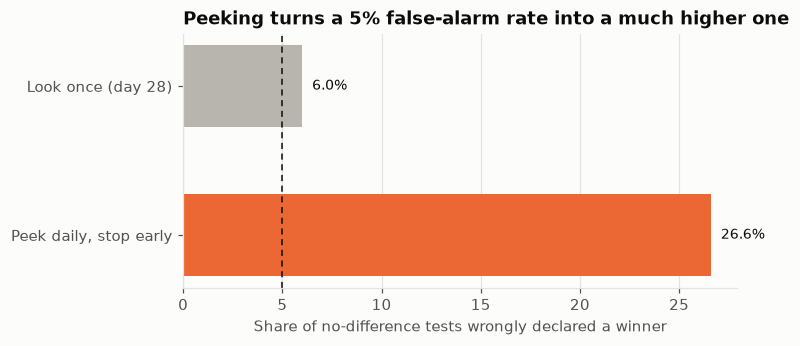

In [5]:
rng = np.random.default_rng(11)
days = 28
per_day = len(s) // days // 2
fp_fixed = fp_peek = 0
for _ in range(1000):
    a = rng.binomial(per_day, p_a, days).cumsum()
    b = rng.binomial(per_day, p_a, days).cumsum()
    n = per_day * np.arange(1, days + 1)
    pooled = (a + b) / (2 * n)
    zt = (b / n - a / n) / np.sqrt(2 * pooled * (1 - pooled) / n)
    pv = 2 * norm.sf(np.abs(zt))
    fp_fixed += pv[-1] < 0.05
    fp_peek += (pv < 0.05).any()
print(f"False-alarm rate, look once at day 28: {fp_fixed / 10:.1f}%")
print(f"False-alarm rate, peek daily and stop at first p < 0.05: {fp_peek / 10:.1f}%")

fig, ax = plt.subplots(figsize=(6.5, 3))
ax.barh([1, 0], [fp_fixed / 10, fp_peek / 10], color=[NEUTRAL, COLOR["qc_ads"]], height=0.55)
for y_, v in zip([1, 0], [fp_fixed / 10, fp_peek / 10]):
    ax.text(v + 0.5, y_, f"{v:.1f}%", va="center", fontsize=9, color=INK)
ax.axvline(5, color=INK, lw=1, ls=(0, (4, 3)))
ax.set_yticks([1, 0], ["Look once (day 28)", "Peek daily, stop early"])
ax.set_xlabel("Share of no-difference tests wrongly declared a winner")
ax.grid(axis="y", visible=False)
ax.set_title("Peeking turns a 5% false-alarm rate into a much higher one")
save(fig, "06_peeking"); plt.show()

## 5. What is the lift worth?
Apply the measured relative lift to the website's last 52 weeks of orders.

In [6]:
w, _ = load(FULL)
last52 = w[w.week > 52]
orders_yr = last52["orders"].sum()
aov = s.loc[s.converted == 1, "order_value_inr"].mean()
rel = diff / pa
rel_lo, rel_hi = ci[0] / pa, ci[1] / pa
extra = lambda r: orders_yr * r * aov / 1e7                     # ₹ Cr
print(f"Website orders, last 52 weeks: {orders_yr:,} | AOV ₹{aov:.0f}")
print(f"Extra revenue a year from rolling out B: ₹{extra(rel):.2f} Cr (95% CI {extra(rel_lo):.2f}–{extra(rel_hi):.2f}); "
      f"at 40% contribution: ₹{extra(rel) * 0.40:.2f} Cr")

Website orders, last 52 weeks: 375,591 | AOV ₹642
Extra revenue a year from rolling out B: ₹2.49 Cr (95% CI 0.97–4.01); at 40% contribution: ₹1.00 Cr


## 6. So what

In [7]:
win = ci[0] > 0
print("SO WHAT")
print(f"1. Result: the 1-page checkout {'raises' if diff > 0 else 'changes'} conversion by {diff * 100:+.2f} pp "
      f"({diff / pa:+.1%} relative; 95% CI {ci[0] * 100:+.2f} to {ci[1] * 100:+.2f} pp). "
      f"{'Statistically clear: roll it out.' if win else 'Not clear enough to roll out on this evidence.'}")
print(f"2. Value: about ₹{extra(rel):.1f} Cr a year of extra website revenue (₹{extra(rel) * 0.40:.1f} Cr contribution) "
      "without any extra ad spend: a non-media lever for the CFO's 20% cap.")
print(f"3. Discipline: the split passed the SRM check; peeking daily would have raised false alarms from "
      f"{fp_fixed / 10:.0f}% to {fp_peek / 10:.0f}%, so results were read once, at the planned end.")

SO WHAT
1. Result: the 1-page checkout raises conversion by +0.34 pp (+10.3% relative; 95% CI +0.13 to +0.54 pp). Statistically clear: roll it out.
2. Value: about ₹2.5 Cr a year of extra website revenue (₹1.0 Cr contribution) without any extra ad spend: a non-media lever for the CFO's 20% cap.
3. Discipline: the split passed the SRM check; peeking daily would have raised false alarms from 6% to 27%, so results were read once, at the planned end.
